# Compare and tune projected-subgradient step-size schedules

First compare inverse-square-root and geometric schedules in the original paired
AR(2) experiment, then compare a grid of geometric schedules
$\eta_t=\eta_0\beta^t$ for the shared minimum-width optimizer. The tuning model is the existing stationary AR(3)
example $\phi=(0.6,-0.3,0.2)$ with uniform innovations on $[-1,1]$, embedding
dimension $k=p+1=4$, and common endpoint $K=5$.

**Question:** after the preliminary schedule-family comparison, which geometric
schedule finds the smallest empirical width within the fixed budget of 12 starts and 3,000 iterations? Use identical clouds and
initial directions for every candidate, select on tuning replications, then
compare the selected schedule with the current baseline on fresh replications.
True coefficients are used for simulation and diagnostic error measurements;
they are not used for initialization or schedule selection.

Sources: the baseline is in [ar3_minimum_width_vs_T.ipynb](ar3_minimum_width_vs_T.ipynb);
the optimizer is [descent.py](ar_tools/descent.py), `batched_geometric_width_curves`.
Your [AR chapter](../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex)
supplies the empirical-width definition and Lemma 6 (weak sharp minima).
[Li et al., §§2.2 and 5.2, Theorem 4](https://arxiv.org/html/1911.05047v4#S5.SS2)
motivate geometric schedules under local sharpness and initialization conditions.
This experiment does not verify those conditions or certify global minima;
the current Lemma 6 proof remains marked TBD in the chapter.


In [1]:
import hashlib                                                                                      ### INFRASTRUCTURE
import json                                                                                         ### INFRASTRUCTURE
import sys                                                                                          ### INFRASTRUCTURE
from itertools import product
from pathlib import Path                                                                            ### INFRASTRUCTURE
from time import perf_counter

import matplotlib.pyplot as plt                                                                     ### PLOTTING
import numpy as np
import pandas as pd
from IPython import get_ipython                                                                     ### PLOTTING
from IPython.display import display                                                                 ### REPORTING
from scipy.spatial import ConvexHull, QhullError
from threadpoolctl import threadpool_limits                                                         ### INFRASTRUCTURE

AR_CODE_DIR = next((                                                                                ### INFRASTRUCTURE
    candidate.resolve()                                                                             ### INFRASTRUCTURE
    for root in (Path.cwd(), *Path.cwd().parents)                                                   ### INFRASTRUCTURE
    for candidate in (root / "Code" / "Code_AR_processes", root)                                    ### INFRASTRUCTURE
    if (candidate / "ar_tools/functions.py").is_file()                                              ### INFRASTRUCTURE
    and (candidate / "ar_tools/descent.py").is_file()                                               ### INFRASTRUCTURE
), None)                                                                                            ### INFRASTRUCTURE
if AR_CODE_DIR is None:                                                                             ### INFRASTRUCTURE
    raise FileNotFoundError("Could not locate Code/Code_AR_processes.")                             ### INFRASTRUCTURE
PROJECT_ROOT = AR_CODE_DIR.parents[1]                                                               ### INFRASTRUCTURE
if str(PROJECT_ROOT) not in sys.path:                                                               ### INFRASTRUCTURE
    sys.path.insert(0, str(PROJECT_ROOT))                                                           ### INFRASTRUCTURE

from Code.Code_AR_processes.ar_tools.descent import (
    batched_geometric_width_curves,
    projected_subgradient_empirical_width,
)
from Code.Code_AR_processes.ar_tools.functions import (
    is_stationary, jones_ar_coefficients, simulate_uniform_ar,
    sliding_window_point_cloud,
)

EXPERIMENT_NAME = "ar_projected_subgradient_eta0_beta_tuning"                                       ### INFRASTRUCTURE
if get_ipython() is not None:                                                                       ### PLOTTING
    get_ipython().run_line_magic("matplotlib", "inline")                                            ### PLOTTING
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,                                     ### PLOTTING
                     "axes.spines.right": False, "pdf.fonttype": 42})                               ### PLOTTING
np.set_printoptions(precision=6, suppress=True)                                                     ### REPORTING


## Preliminary step-size schedule comparison

Before tuning the geometric parameters, this paired experiment compares the inverse-square-root and geometric schedule families on one fixed simulated AR(2) series and identical initial directions. The AR(2) fixture reproduces the original comparison from the order-selection notebook: coefficient seed 42, process seed 20260806, sample size 1,000, and burn-in 500. Each schedule uses five starts per embedding dimension, 1,000 iterations, $\eta_0=0.2$, and $\beta=0.99$. Thus the only difference within each pair is

$$\eta_t=\frac{\eta_0}{\sqrt{t+1}} \qquad\text{or}\qquad \eta_t=\eta_0\beta^t.$$


In [6]:
schedule_comparison_phi = jones_ar_coefficients(
    2, rng=42, return_pacf=False
)
schedule_comparison_series = simulate_uniform_ar(
    schedule_comparison_phi, sample_size=1_000, burnin=500,
    half_width=1.0, rng=20260806,
)

schedule_comparison_dimensions = [2, 3, 5, 10, 25, 100]
schedule_comparison_starts = 5
schedule_comparison_iterations = 1_000
schedule_comparison_initial_step = 0.2
schedule_comparison_geometric_decay = 0.99
schedule_comparison_rng = np.random.default_rng(20260813)
schedule_comparison_rows = []

for dimension in schedule_comparison_dimensions:
    cloud = sliding_window_point_cloud(schedule_comparison_series, dimension)
    initial_directions = schedule_comparison_rng.normal(
        size=(schedule_comparison_starts, dimension)
    )
    initial_directions /= np.linalg.norm(
        initial_directions, axis=1, keepdims=True
    )

    for start_index, initial_direction in enumerate(initial_directions):
        for step_schedule in ("inverse_sqrt", "geometric"):
            start_time = perf_counter()
            fit = projected_subgradient_empirical_width(
                cloud,
                iterations=schedule_comparison_iterations,
                initial_step=schedule_comparison_initial_step,
                step_schedule=step_schedule,
                geometric_decay=schedule_comparison_geometric_decay,
                patience=schedule_comparison_iterations,
                improvement_tolerance=0.0,
                initial_direction=initial_direction,
                rng=1_000 + dimension + start_index,
            )
            schedule_comparison_rows.append({
                "k": dimension,
                "start": start_index,
                "step_schedule": step_schedule,
                "minimum_width": fit["minimum_width"],
                "seconds": perf_counter() - start_time,
            })

schedule_comparison = pd.DataFrame(schedule_comparison_rows)
paired_widths = schedule_comparison.pivot(
    index=["k", "start"],
    columns="step_schedule",
    values="minimum_width",
)
median_widths = paired_widths.groupby(level="k").median()
schedule_comparison_summary = median_widths.copy()
schedule_comparison_summary["geometric_wins"] = (
    paired_widths["geometric"] < paired_widths["inverse_sqrt"]
).groupby(level="k").sum()
schedule_comparison_summary["relative_improvement_percent"] = (
    100.0
    * (schedule_comparison_summary["inverse_sqrt"]
       - schedule_comparison_summary["geometric"])
    / schedule_comparison_summary["inverse_sqrt"]
)

display(schedule_comparison_summary.round(6))                                                       ### REPORTING
print(                                                                                              ### REPORTING
    "Overall paired wins for the geometric schedule:",                                              ### REPORTING
    int((paired_widths["geometric"] < paired_widths["inverse_sqrt"]).sum()),                        ### REPORTING
    "out of",                                                                                       ### REPORTING
    len(paired_widths),                                                                             ### REPORTING
)                                                                                                   ### REPORTING


step_schedule,geometric,inverse_sqrt,geometric_wins,relative_improvement_percent
k,,,,
2,8.803711,8.803923,5,0.002415
3,1.136173,1.157649,5,1.855213
5,1.113758,1.328418,5,16.159066
10,1.153020,1.509784,5,23.630108
25,1.111650,1.809104,5,38.552473
100,1.250909,2.770756,5,54.853158


Overall paired wins for the geometric schedule: 30 out of 30


With seed 20260813, the geometric schedule won all 30 paired trials. The observed median minimum widths were:

| $k$ | Geometric | Inverse square root | Geometric wins |
|---:|---:|---:|---:|
| 2 | 8.803711 | 8.803923 | 5/5 |
| 3 | 1.136173 | 1.157649 | 5/5 |
| 5 | 1.113758 | 1.328418 | 5/5 |
| 10 | 1.153020 | 1.509784 | 5/5 |
| 25 | 1.111650 | 1.809104 | 5/5 |
| 100 | 1.250909 | 2.770756 | 5/5 |

For this fixed series, starts, iteration budget, and parameter pair, the geometric schedule attains the smaller recorded width in every comparison. At iteration 1,000, the inverse-square-root step is approximately $0.0063$, whereas the geometric step is approximately $8.7\times10^{-6}$; this direct calculation explains how different the terminal step scales are but does not by itself establish why one run attained a smaller width. This is an empirical comparison, not a universal guarantee: [Li et al., §§2.2 and 5.2, Theorem 4](https://arxiv.org/html/1911.05047v4#S5.SS2) gives a local result whose admissible $\eta_0$ and $\beta$ depend on sharpness and initialization conditions.


## Settings and the meaning of $\eta_0$

With `step_mode="box_normalized"`, the grid entries are scales $c$ and the
actual initial step for each cloud is $\eta_0=c/L_{\mathrm{box}}$, where
$L_{\mathrm{box}}=\|\operatorname{ptp}(P,\mathrm{axis}=0)\|_2$.
This follows the existing experiment's normalization; actual $\eta_0$ values
are retained in the result CSVs. Set `step_mode="absolute"` to interpret the
same grid as literal $\eta_0$ values. The baseline always remains
$\eta_0=0.2/L_{\mathrm{box}}$, $\beta=0.995$.
Source: [baseline normalization](ar3_minimum_width_vs_T.ipynb), optimization cell.

Defaults give 30 candidate pairs on six tuning paths at two sample sizes.
Prefixes of the same path are paired across sample sizes. Six separate paths
are reserved for the baseline comparison. Edit the grid and replication
counts here; use the same iteration budget as the intended final experiment.
This is a choice for this study, not a universal optimality claim.


In [2]:
phi = np.array([0.6, -0.3, 0.2], dtype=float)
T_values = np.array([500, 2_000], dtype=int)
k = len(phi) + 1
K = 5
burnin = 2_000
innovations_half_width = 1.0

step_mode = "box_normalized"  # Or "absolute" for literal eta_0 values.
initial_step_grid = np.array([0.025, 0.05, 0.1, 0.2, 0.4, 0.8])
beta_grid = np.array([0.97, 0.99, 0.995, 0.997, 0.999])
number_of_starts = 12
optimization_iterations = 3_000
tuning_replications = 6
validation_replications = 6
process_seed = 20260918
optimizer_seed = 20260919
use_convex_hull = True
resume = True                                                                                       ### INFRASTRUCTURE
invalid_u0_threshold = 1e-10
baseline_scale = 0.2
baseline_beta = 0.995

if phi.ndim != 1 or len(phi) < 1 or not np.all(np.isfinite(phi)):
    raise ValueError("Use a finite, nonempty coefficient vector.")
if phi[-1] == 0 or not is_stationary(phi)[0]:
    raise ValueError("Use a stationary AR process with nonzero last coefficient.")
if (T_values.ndim != 1 or len(T_values) == 0
        or np.any(np.diff(T_values) <= 0) or T_values[0] <= K):
    raise ValueError("T_values must be increasing and exceed K.")
if not isinstance(K, (int, np.integer)) or K < k:
    raise ValueError("Use integer K >= p+1.")
for name in ("number_of_starts", "optimization_iterations", "tuning_replications",
             "validation_replications", "burnin", "process_seed", "optimizer_seed"):
    value = globals()[name]
    minimum = 0 if name in {"burnin", "process_seed", "optimizer_seed"} else 1
    if not isinstance(value, (int, np.integer)) or value < minimum:
        raise ValueError(f"Invalid integer setting: {name}.")
if step_mode not in {"box_normalized", "absolute"}:
    raise ValueError("step_mode must be box_normalized or absolute.")
for grid, name in ((initial_step_grid, "initial_step_grid"), (beta_grid, "beta_grid")):
    if (grid.ndim != 1 or len(grid) == 0 or not np.all(np.isfinite(grid))
            or len(np.unique(grid)) != len(grid)):
        raise ValueError(f"Use distinct finite values in {name}.")
if np.any(initial_step_grid <= 0) or np.any((beta_grid <= 0) | (beta_grid >= 1)):
    raise ValueError("Initial steps must be positive; beta must be in (0,1).")
if not np.isfinite(innovations_half_width) or innovations_half_width <= 0:
    raise ValueError("Use a positive finite innovation half-width.")
if not isinstance(use_convex_hull, (bool, np.bool_)):
    raise ValueError("use_convex_hull must be boolean.")
if not np.isfinite(invalid_u0_threshold) or invalid_u0_threshold <= 0:
    raise ValueError("Use a positive finite coefficient-recovery threshold.")

candidates = [
    {"candidate_id": f"grid_{index:03d}", "step_value": float(step),
     "beta": float(beta), "step_mode": step_mode}
    for index, (step, beta) in enumerate(product(initial_step_grid, beta_grid))
]
baseline = {"candidate_id": "baseline", "step_value": baseline_scale,
            "beta": baseline_beta, "step_mode": "box_normalized"}
configuration = {                                                                                   ### INFRASTRUCTURE
    "experiment_version": 1, "phi": phi.tolist(), "T_values": T_values.tolist(),                    ### INFRASTRUCTURE
    "k": k, "K": K, "burnin": burnin, "half_width": innovations_half_width,                         ### INFRASTRUCTURE
    "candidates": candidates, "baseline": baseline,                                                 ### INFRASTRUCTURE
    "starts": number_of_starts, "iterations": optimization_iterations,                              ### INFRASTRUCTURE
    "tuning_replications": tuning_replications,                                                     ### INFRASTRUCTURE
    "validation_replications": validation_replications,                                             ### INFRASTRUCTURE
    "process_seed": process_seed, "optimizer_seed": optimizer_seed,                                 ### INFRASTRUCTURE
    "use_convex_hull": use_convex_hull, "invalid_u0_threshold": invalid_u0_threshold,               ### INFRASTRUCTURE
    "selection_metric": "mean_relative_width_gap",                                                  ### INFRASTRUCTURE
    "source_sha256": hashlib.sha256(                                                                ### INFRASTRUCTURE
        (AR_CODE_DIR / "ar_tools/functions.py").read_bytes()                                        ### INFRASTRUCTURE
        + (AR_CODE_DIR / "ar_tools/descent.py").read_bytes()                                        ### INFRASTRUCTURE
    ).hexdigest(),                                                                                  ### INFRASTRUCTURE
}                                                                                                   ### INFRASTRUCTURE
# Hash the notebook's cell sources, excluding saved outputs/execution metadata.                     ### INFRASTRUCTURE
notebook_source = json.loads((AR_CODE_DIR / f"{EXPERIMENT_NAME}.ipynb").read_text())                ### INFRASTRUCTURE
configuration["notebook_source_sha256"] = hashlib.sha256(json.dumps([                               ### INFRASTRUCTURE
    (cell["cell_type"], "".join(cell["source"])) for cell in notebook_source["cells"]               ### INFRASTRUCTURE
], sort_keys=True).encode()).hexdigest()                                                            ### INFRASTRUCTURE
config_text = json.dumps(configuration, sort_keys=True, indent=2)                                   ### INFRASTRUCTURE
run_id = hashlib.sha256(config_text.encode()).hexdigest()[:16]                                      ### INFRASTRUCTURE
CSV_DIR = AR_CODE_DIR / "outputs" / "csv" / EXPERIMENT_NAME / run_id                                ### INFRASTRUCTURE
PDF_DIR = AR_CODE_DIR / "outputs" / "pdfs" / EXPERIMENT_NAME / run_id                               ### INFRASTRUCTURE
IMAGE_DIR = AR_CODE_DIR / "outputs" / "images" / EXPERIMENT_NAME / run_id                           ### INFRASTRUCTURE
for directory in (CSV_DIR, PDF_DIR, IMAGE_DIR):                                                     ### INFRASTRUCTURE
    directory.mkdir(parents=True, exist_ok=True)                                                    ### INFRASTRUCTURE
(CSV_DIR / "configuration.json").write_text(config_text + "\n")                                     ### INFRASTRUCTURE

def save_figure(figure, name):                                                                      ### PLOTTING
    figure.savefig(PDF_DIR / f"{name}.pdf", bbox_inches="tight")                                    ### PLOTTING
    figure.savefig(IMAGE_DIR / f"{name}.png", dpi=160, bbox_inches="tight")                         ### PLOTTING

print(f"Run ID: {run_id}; mode: {step_mode}")                                                       ### REPORTING
print(f"Grid: {len(candidates)} pairs; {number_of_starts} starts; "                                 ### REPORTING
      f"{optimization_iterations:,} iterations per start")                                          ### REPORTING
print(f"Tuning fits: {len(candidates) * tuning_replications * len(T_values):,}")                    ### REPORTING
print(f"Results: {CSV_DIR}")                                                                        ### REPORTING


Run ID: 685def7e60c3548b; mode: box_normalized
Grid: 30 pairs; 12 starts; 3,000 iterations per start
Tuning fits: 360
Results: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar_projected_subgradient_eta0_beta_tuning/685def7e60c3548b


## Paired runs and diagnostics

Each candidate uses the same seeded random starts for a given replication
and $T$. The batched optimizer
uses its full iteration budget and returns the best evaluated iterate.
Convex-hull evaluation is optional; the saved direction's width is checked
on the full cloud. Source: [descent.py](ar_tools/descent.py), `batched_geometric_width_curves`.

For this simulation, also record $\widehat\phi=-\widehat u_{1:p}/\widehat u_0$,
using newest-first coordinates. This is obtained by matching the direction's
linear form to $X_t-\sum_j\widehat\phi_jX_{t-j}$; it follows the existing
[coefficient experiment](ar3_minimum_width_vs_T.ipynb). Near-zero
$\widehat u_0$ is recorded as invalid. Coefficient RMSE is reported only if
every estimate in a candidate's group is valid; no failed estimates are dropped.

Completed cases are cached in a folder determined by settings and source
hashes. Rerunning identical settings reuses them. An invalid cached case
triggers an error rather than silently combining inconsistent results.


In [3]:
def make_case(phase, replication, T):
    phase_index = {"tuning": 0, "validation": 1}[phase]
    series = simulate_uniform_ar(
        phi, sample_size=int(T_values[-1]), burnin=burnin,
        half_width=innovations_half_width,
        rng=np.random.default_rng(np.random.SeedSequence([
            process_seed, phase_index, int(replication),
        ])),
    )
    series_for_k = series[K - k:int(T)]
    cloud = sliding_window_point_cloud(series_for_k, k)
    if cloud.shape != (int(T) - K + 1, k) or not np.all(np.isfinite(cloud)):
        raise RuntimeError("Invalid common-endpoint cloud.")
    bound = float(np.linalg.norm(np.ptp(cloud, axis=0)))
    if not np.isfinite(bound) or bound <= 0:
        raise ValueError("The cloud must have positive finite width.")
    optimizer_replication = phase_index * 1_000_000 + int(replication)
    return series_for_k, cloud, bound, optimizer_replication

def fit_candidate(case, candidate):
    series, cloud, bound, optimizer_replication = case
    eta0 = candidate["step_value"]
    if candidate["step_mode"] == "box_normalized":
        eta0 /= bound
    start_time = perf_counter()
    single, widths, _, directions = batched_geometric_width_curves(
        series, k, seed=optimizer_seed, replication=optimizer_replication,
        starts=number_of_starts, iterations=optimization_iterations,
        initial_step=eta0, geometric_decay=candidate["beta"],
        return_directions=True, use_convex_hull=use_convex_hull,
    )
    elapsed = perf_counter() - start_time
    direction = directions[k - 1]
    width = float(np.ptp(cloud @ direction))
    if (not np.all(np.isfinite(direction)) or not np.isfinite(width)
            or not np.isclose(np.linalg.norm(direction), 1.0, atol=1e-10)
            or not np.isclose(width, widths[k - 1], atol=1e-10, rtol=1e-10)):
        raise RuntimeError("Returned direction does not reproduce a finite width.")
    valid = abs(direction[0]) >= invalid_u0_threshold
    estimate = -direction[1:] / direction[0] if valid else np.full(len(phi), np.nan)
    valid = bool(valid and np.all(np.isfinite(estimate)))
    error = float(np.linalg.norm(estimate - phi)) if valid else np.nan
    row = dict(candidate, eta0=float(eta0), lipschitz_bound=bound,
               minimum_width=width, first_random_start_width=float(single[k - 1]),
               runtime_seconds=elapsed, coefficient_valid=valid,
               coefficient_error=error,
               squared_coefficient_error=error**2 if valid else np.nan)
    for j, value in enumerate(direction):
        row[f"u_{j}"] = float(value)
    for j, value in enumerate(estimate):
        row[f"estimated_phi_{j+1}"] = float(value)
    return row

def run_phase(phase, replication_count, phase_candidates):
    frames = []
    phase_start = perf_counter()
    with threadpool_limits(limits=1):                                                               ### INFRASTRUCTURE
        for replication in range(replication_count):
            for T in T_values:
                cache_path = CSV_DIR / f"{phase}_r{replication:03d}_T{int(T)}.csv"                  ### INFRASTRUCTURE
                if resume and cache_path.exists():                                                  ### INFRASTRUCTURE
                    frame = pd.read_csv(cache_path)                                                 ### INFRASTRUCTURE
                    expected_ids = {c["candidate_id"] for c in phase_candidates}                    ### INFRASTRUCTURE
                    if (len(frame) != len(expected_ids)                                             ### INFRASTRUCTURE
                            or set(frame["candidate_id"]) != expected_ids                           ### INFRASTRUCTURE
                            or not (frame["phase"] == phase).all()                                  ### INFRASTRUCTURE
                            or not (frame["replication"] == replication).all()                      ### INFRASTRUCTURE
                            or not (frame["T"] == int(T)).all()                                     ### INFRASTRUCTURE
                            or not np.isfinite(frame["minimum_width"]).all()):                      ### INFRASTRUCTURE
                        raise RuntimeError(f"Inconsistent cached case: {cache_path}")               ### INFRASTRUCTURE
                else:                                                                               ### INFRASTRUCTURE
                    case = make_case(phase, replication, int(T))
                    rows = [dict(fit_candidate(case, candidate), phase=phase,
                                 replication=replication, T=int(T))
                            for candidate in phase_candidates]
                    frame = pd.DataFrame(rows)
                    temporary = cache_path.with_suffix(".tmp.csv")                                  ### INFRASTRUCTURE
                    frame.to_csv(temporary, index=False)                                            ### INFRASTRUCTURE
                    temporary.replace(cache_path)                                                   ### INFRASTRUCTURE
                frames.append(frame)
                print(f"{phase}: replication {replication+1}/{replication_count}, "                 ### REPORTING
                      f"T={int(T):,}; elapsed {perf_counter()-phase_start:.1f}s", flush=True)       ### REPORTING
    result = pd.concat(frames, ignore_index=True)
    result.to_csv(CSV_DIR / f"{phase}_results.csv", index=False)                                    ### INFRASTRUCTURE
    return result

tuning_results = run_phase("tuning", tuning_replications, candidates)


tuning: replication 1/6, T=500; elapsed 3.6s
tuning: replication 1/6, T=2,000; elapsed 7.5s
tuning: replication 2/6, T=500; elapsed 11.8s
tuning: replication 2/6, T=2,000; elapsed 16.4s
tuning: replication 3/6, T=500; elapsed 20.0s
tuning: replication 3/6, T=2,000; elapsed 23.8s
tuning: replication 4/6, T=500; elapsed 27.4s
tuning: replication 4/6, T=2,000; elapsed 31.4s
tuning: replication 5/6, T=500; elapsed 35.1s
tuning: replication 5/6, T=2,000; elapsed 40.1s
tuning: replication 6/6, T=500; elapsed 43.7s
tuning: replication 6/6, T=2,000; elapsed 47.9s


## Select on attained width

This study's selection score is the mean relative width gap to the best
grid candidate **on each tuning cloud**:
$g_{r,T}(c,\beta)=(\widehat w_{r,T}(c,\beta)-w^{\mathrm{grid}}_{r,T})/
\max(w^{\mathrm{grid}}_{r,T},10^{-12})$.
Average over replications and sample sizes, giving each cloud equal weight.
The reference is a numerical grid result, not a known global minimum.
Ties in mean score are broken deterministically by the grid's step value
and then $\beta$. Coefficient error is a diagnostic, not the selection criterion.

Also show the actual initial steps and terminal steps. The schedule half-life
$\log(1/2)/\log(\beta)$ is a direct algebraic consequence of $\beta^t=1/2$;
it helps interpret how quickly candidates exhaust their steps.


In [4]:
case_keys = ["replication", "T"]
tuning_results["grid_best_width"] = tuning_results.groupby(case_keys)[
    "minimum_width"].transform("min")
tuning_results["relative_width_gap"] = (
    (tuning_results["minimum_width"] - tuning_results["grid_best_width"])
    / tuning_results["grid_best_width"].clip(lower=1e-12)
)
tuning_results["grid_win"] = tuning_results["relative_width_gap"] <= 1e-10
tuning_results.to_csv(CSV_DIR / "tuning_results.csv", index=False)                                  ### INFRASTRUCTURE

def coefficient_rmse(values):
    values = np.asarray(values, dtype=float)
    return float(np.sqrt(np.mean(values))) if np.isfinite(values).all() else np.nan

ranking = tuning_results.groupby(["candidate_id", "step_value", "beta", "step_mode"]).agg(
    mean_relative_width_gap=("relative_width_gap", "mean"),
    worst_relative_width_gap=("relative_width_gap", "max"),
    grid_win_fraction=("grid_win", "mean"),
    coefficient_rmse=("squared_coefficient_error", coefficient_rmse),
    invalid_coefficient_count=("coefficient_valid", lambda x: int((~x.astype(bool)).sum())),
    mean_runtime_seconds=("runtime_seconds", "mean"),
    eta0_min=("eta0", "min"), eta0_max=("eta0", "max"),
    fit_count=("minimum_width", "size"),
).reset_index().sort_values(
    ["mean_relative_width_gap", "step_value", "beta"], kind="stable",
).reset_index(drop=True)
ranking.insert(0, "rank", np.arange(1, len(ranking)+1))
ranking["schedule_half_life"] = np.log(0.5) / np.log(ranking["beta"])
ranking["eta_last_min"] = ranking["eta0_min"] * ranking["beta"]**(optimization_iterations-1)
ranking["eta_last_max"] = ranking["eta0_max"] * ranking["beta"]**(optimization_iterations-1)
ranking.to_csv(CSV_DIR / "candidate_ranking.csv", index=False)                                      ### INFRASTRUCTURE
selected = dict(next(c for c in candidates if c["candidate_id"] == ranking.iloc[0]["candidate_id"]))
print("Selected from tuning data only:", selected)                                                  ### REPORTING
display(ranking.head(10).round(8))                                                                  ### REPORTING

ranking_by_T = tuning_results.groupby(["T", "candidate_id", "step_value", "beta"]).agg(
    mean_relative_width_gap=("relative_width_gap", "mean"),
    coefficient_rmse=("squared_coefficient_error", coefficient_rmse),
).reset_index()
ranking_by_T.to_csv(CSV_DIR / "ranking_by_sample_size.csv", index=False)                            ### INFRASTRUCTURE


Selected from tuning data only: {'candidate_id': 'grid_007', 'step_value': 0.05, 'beta': 0.995, 'step_mode': 'box_normalized'}


,rank,candidate_id,step_value,beta,step_mode,mean_relative_width_gap,worst_relative_width_gap,grid_win_fraction,coefficient_rmse,invalid_coefficient_count,mean_runtime_seconds,eta0_min,eta0_max,fit_count,schedule_half_life,eta_last_min,eta_last_max
0,1,grid_007,0.050,0.995,box_normalized,0.000000e+00,0.000000e+00,0.333333,0.078788,0,0.127943,0.007274,0.008781,12,138.282573,0.000000e+00,0.000000e+00
1,2,grid_017,0.200,0.995,box_normalized,0.000000e+00,0.000000e+00,0.000000,0.078787,0,0.128447,0.029097,0.035125,12,138.282573,1.000000e-08,1.000000e-08
2,3,grid_003,0.025,0.997,box_normalized,4.000000e-08,8.000000e-08,0.000000,0.078787,0,0.135827,0.003637,0.004391,12,230.702313,4.400000e-07,5.400000e-07
3,4,grid_008,0.050,0.997,box_normalized,8.000000e-08,1.600000e-07,0.000000,0.078786,0,0.131689,0.007274,0.008781,12,230.702313,8.900000e-07,1.070000e-06
4,5,grid_013,0.100,0.997,box_normalized,1.700000e-07,3.900000e-07,0.000000,0.078785,0,0.128830,0.014549,0.017563,12,230.702313,1.780000e-06,2.140000e-06
5,6,grid_021,0.400,0.990,box_normalized,2.800000e-07,3.400000e-06,0.916667,0.078753,0,0.124460,0.058194,0.070250,12,68.967564,0.000000e+00,0.000000e+00
6,7,grid_018,0.200,0.997,box_normalized,3.300000e-07,7.900000e-07,0.000000,0.078784,0,0.134029,0.029097,0.035125,12,230.702313,3.550000e-06,4.290000e-06
7,8,grid_026,0.800,0.990,box_normalized,3.400000e-07,4.110000e-06,0.916667,0.078746,0,0.143906,0.116389,0.140500,12,68.967564,0.000000e+00,0.000000e+00
8,9,grid_004,0.025,0.999,box_normalized,1.313000e-05,3.505000e-05,0.000000,0.078596,0,0.142189,0.003637,0.004391,12,692.800549,1.809900e-04,2.184900e-04
9,10,grid_009,0.050,0.999,box_normalized,2.591000e-05,6.186000e-05,0.000000,0.078412,0,0.133654,0.007274,0.008781,12,692.800549,3.619800e-04,4.369700e-04


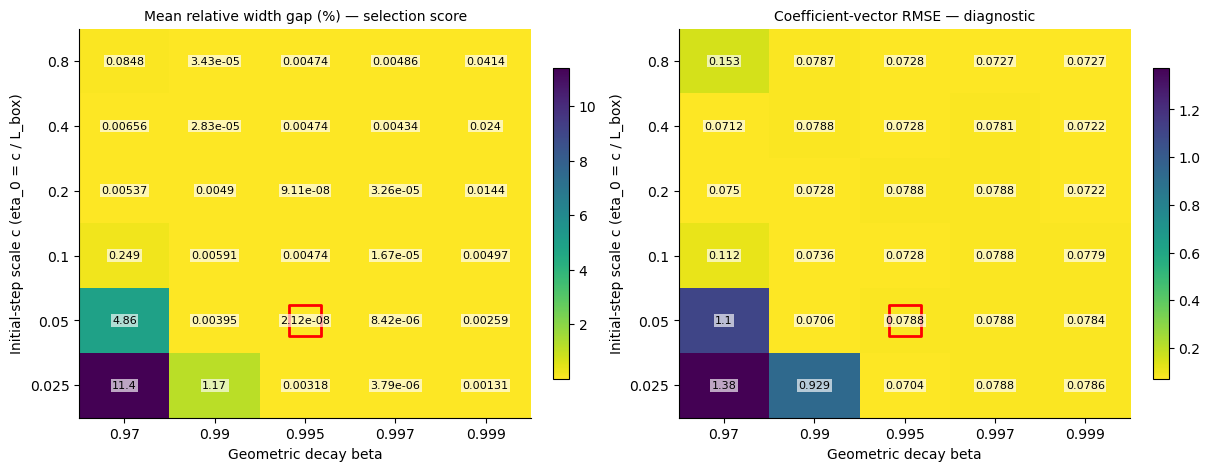

In [5]:
x_values = np.sort(beta_grid)                                                                       ### PLOTTING
y_values = np.sort(initial_step_grid)                                                               ### PLOTTING
axis_label = (                                                                                      ### PLOTTING
    "Initial-step scale c (eta_0 = c / L_box)"                                                      ### PLOTTING
    if step_mode == "box_normalized"                                                                ### PLOTTING
    else "Initial step eta_0"                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)                          ### PLOTTING
for ax, metric, title in zip(axes,                                                                  ### PLOTTING
        ["mean_relative_width_gap", "coefficient_rmse"],                                            ### PLOTTING
        ["Mean relative width gap (%) — selection score", "Coefficient-vector RMSE — diagnostic"]): ### PLOTTING
    matrix = ranking.pivot(index="step_value", columns="beta", values=metric).reindex(              ### PLOTTING
        index=y_values, columns=x_values)                                                           ### PLOTTING
    values = matrix.to_numpy() * (100 if metric == "mean_relative_width_gap" else 1)                ### PLOTTING
    im = ax.imshow(np.ma.masked_invalid(values), aspect="auto", origin="lower", cmap="viridis_r")   ### PLOTTING
    ax.set_xticks(np.arange(len(x_values)), [f"{b:g}" for b in x_values])                           ### PLOTTING
    ax.set_yticks(np.arange(len(y_values)), [f"{s:g}" for s in y_values])                           ### PLOTTING
    ax.set_xlabel("Geometric decay beta")                                                           ### PLOTTING
    ax.set_ylabel(axis_label)                                                                       ### PLOTTING
    ax.set_title(title, fontsize=10)                                                                ### PLOTTING
    for i in range(len(y_values)):                                                                  ### PLOTTING
        for j in range(len(x_values)):                                                              ### PLOTTING
            value = values[i, j]                                                                    ### PLOTTING
            ax.text(j, i, f"{value:.3g}" if np.isfinite(value) else "invalid",                      ### PLOTTING
                    ha="center", va="center", color="black", fontsize=8,                            ### PLOTTING
                    bbox={"facecolor": "white", "alpha": .65, "edgecolor": "none", "pad": 1})       ### PLOTTING
    ax.scatter(np.where(x_values == selected["beta"])[0],                                           ### PLOTTING
               np.where(y_values == selected["step_value"])[0],                                     ### PLOTTING
               marker="s", s=520, facecolors="none", edgecolors="red", linewidths=2)                ### PLOTTING
    fig.colorbar(im, ax=ax, shrink=.8)                                                              ### PLOTTING
save_figure(fig, "01_parameter_grid")                                                               ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING


## Fresh-sample comparison with the current baseline

Freeze the selected pair before running validation. The selected pair and
baseline share validation clouds and starts. Report paired width differences,
coefficient RMSE, invalid coefficient counts, and runtime at each $T$.
A negative relative width difference favors the selected schedule.
Validation does not revise the selection. Matching schedules provide a useful
reproducibility check and should have identical widths and directions.


validation: replication 1/6, T=500; elapsed 0.4s
validation: replication 1/6, T=2,000; elapsed 1.0s
validation: replication 2/6, T=500; elapsed 1.3s
validation: replication 2/6, T=2,000; elapsed 1.6s
validation: replication 3/6, T=500; elapsed 1.9s
validation: replication 3/6, T=2,000; elapsed 2.2s
validation: replication 4/6, T=500; elapsed 2.4s
validation: replication 4/6, T=2,000; elapsed 2.7s
validation: replication 5/6, T=500; elapsed 3.0s
validation: replication 5/6, T=2,000; elapsed 3.3s
validation: replication 6/6, T=500; elapsed 3.5s
validation: replication 6/6, T=2,000; elapsed 3.8s


,T,candidate_id,mean_width,coefficient_rmse,invalid_coefficient_count,mean_runtime_seconds,eta0_min,eta0_max
0,500,baseline,1.607180,0.098741,0,0.155687,0.030046,0.033822
1,500,selected,1.607180,0.098741,0,0.124841,0.007512,0.008455
2,2000,baseline,1.633363,0.011108,0,0.134084,0.029454,0.030664
3,2000,selected,1.633363,0.011142,0,0.172554,0.007363,0.007666


,mean_relative_width_difference,worst_relative_width_difference,selected_width_wins
T,,,
500,-5.783738e-10,-2.457175e-10,6
2000,2.517656e-08,5.281447e-07,5


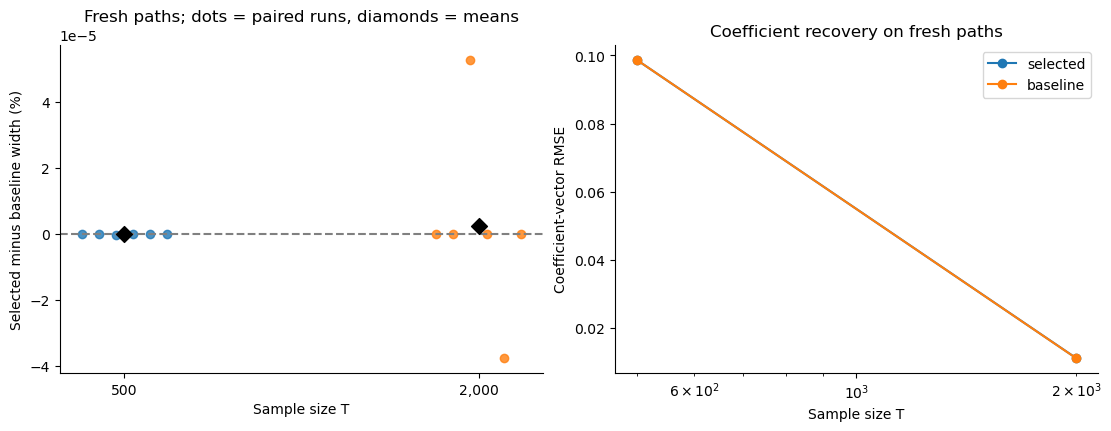

In [6]:
validation_candidates = [dict(selected, candidate_id="selected"), baseline]
validation_results = run_phase("validation", validation_replications, validation_candidates)
comparison = validation_results.pivot(index=["replication", "T"],
    columns="candidate_id", values="minimum_width").reset_index()
comparison["selected_minus_baseline_width"] = comparison["selected"] - comparison["baseline"]
comparison["relative_width_difference"] = (
    comparison["selected_minus_baseline_width"] / comparison["baseline"].clip(lower=1e-12)
)
comparison.to_csv(CSV_DIR / "validation_paired_comparison.csv", index=False)                        ### INFRASTRUCTURE
validation_summary = validation_results.groupby(["T", "candidate_id"]).agg(
    mean_width=("minimum_width", "mean"),
    coefficient_rmse=("squared_coefficient_error", coefficient_rmse),
    invalid_coefficient_count=("coefficient_valid", lambda x: int((~x.astype(bool)).sum())),
    mean_runtime_seconds=("runtime_seconds", "mean"),
    eta0_min=("eta0", "min"), eta0_max=("eta0", "max"),
).reset_index()
validation_summary.to_csv(CSV_DIR / "validation_summary.csv", index=False)                          ### INFRASTRUCTURE
display(validation_summary.round(8))                                                                ### REPORTING
display(comparison.groupby("T").agg(                                                                ### REPORTING
    mean_relative_width_difference=("relative_width_difference", "mean"),                           ### REPORTING
    worst_relative_width_difference=("relative_width_difference", "max"),                           ### REPORTING
    selected_width_wins=("relative_width_difference", lambda x: int((x < -1e-10).sum())),           ### REPORTING
))                                                                                                  ### REPORTING

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)                          ### PLOTTING
for index, T in enumerate(T_values):                                                                ### PLOTTING
    values = comparison.loc[                                                                        ### PLOTTING
        comparison["T"] == int(T), "relative_width_difference"                                      ### PLOTTING
    ].to_numpy() * 100                                                                              ### PLOTTING
    jitter = np.linspace(-0.12, 0.12, len(values))                                                  ### PLOTTING
    axes[0].scatter(index+jitter, values, alpha=.8)                                                 ### PLOTTING
    axes[0].scatter(index, np.mean(values), marker="D", s=65, color="black", zorder=3)              ### PLOTTING
axes[0].axhline(0, color="gray", linestyle="--")                                                    ### PLOTTING
axes[0].set_xticks(np.arange(len(T_values)), [f"{int(T):,}" for T in T_values])                     ### PLOTTING
axes[0].set(xlabel="Sample size T", ylabel="Selected minus baseline width (%)",                     ### PLOTTING
            title="Fresh paths; dots = paired runs, diamonds = means")                              ### PLOTTING
for label in ["selected", "baseline"]:                                                              ### PLOTTING
    frame = validation_summary[validation_summary["candidate_id"] == label]                         ### PLOTTING
    axes[1].plot(frame["T"], frame["coefficient_rmse"], "o-", label=label)                          ### PLOTTING
axes[1].set(xlabel="Sample size T", ylabel="Coefficient-vector RMSE",                               ### PLOTTING
            title="Coefficient recovery on fresh paths")                                            ### PLOTTING
axes[1].set_xscale("log")                                                                           ### PLOTTING
axes[1].legend()                                                                                    ### PLOTTING
save_figure(fig, "02_fresh_sample_comparison")                                                      ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING


## Inspect the trajectories

On the first tuning path at the largest $T$, rerun the three highest-ranked
candidates and the baseline with the standalone optimizer to obtain histories.
Recreate the batched starts exactly; disable patience stopping and set the
improvement tolerance to zero. Stationarity may still terminate a trajectory.
The histories and attained directions are checked against the batched results.
Sources: [descent.py](ar_tools/descent.py), both optimizer functions.

The plots show the best width across starts at each evaluated iteration,
the relative gap to the smallest plotted attained width, and the step schedule.
The plotted reference is numerical. A flat best-width curve shows that no
further improvement was found in that run; it does not certify convergence.


Trace checked: grid_007: c=0.05, beta=0.995; width=1.6314517975
Trace checked: grid_017: c=0.2, beta=0.995; width=1.6314517991
Trace checked: grid_003: c=0.025, beta=0.997; width=1.6314519219
Trace checked: baseline: c=0.2, beta=0.995; width=1.6314517991


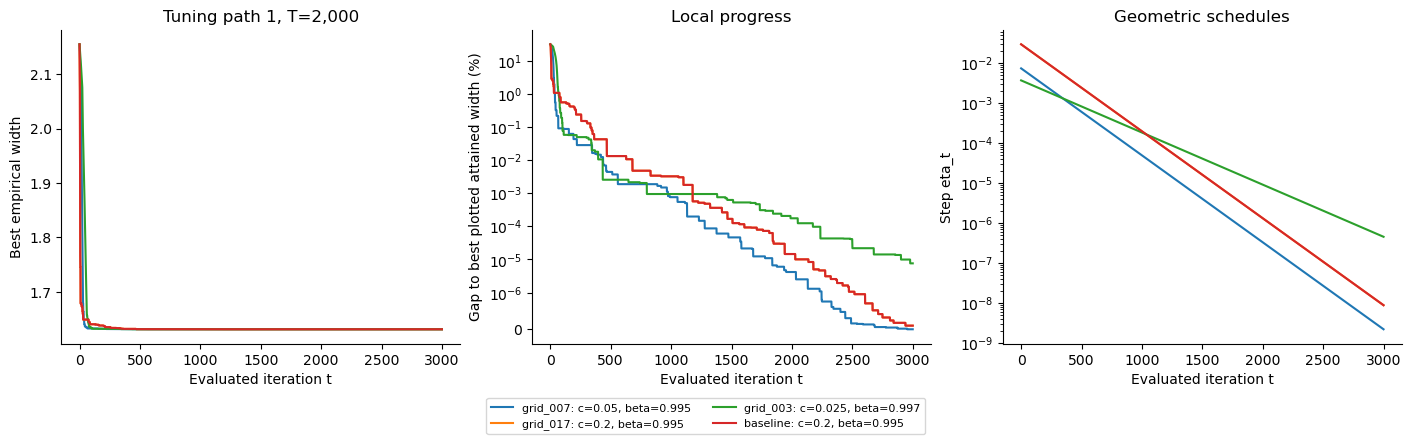

In [7]:
trace_T = int(T_values[-1])
trace_case = make_case("tuning", 0, trace_T)
_, trace_cloud, trace_bound, trace_replication = trace_case
_, eigenvectors = np.linalg.eigh(np.cov(trace_cloud, rowvar=False))
initial_generator = np.random.default_rng(np.random.SeedSequence([
    optimizer_seed, trace_replication, k, 20,
]))
initial_directions = np.vstack([eigenvectors[:, 0]] + [
    initial_generator.normal(size=k) for _ in range(number_of_starts-1)])
initial_directions /= np.linalg.norm(initial_directions, axis=1, keepdims=True)
trace_optimization_cloud = trace_cloud
if use_convex_hull and k >= 2 and len(trace_cloud) > k:
    try:
        trace_optimization_cloud = trace_cloud[np.sort(ConvexHull(trace_cloud).vertices)]
    except QhullError:
        pass
trace_candidates = [dict(next(c for c in candidates if c["candidate_id"] == candidate_id))
                    for candidate_id in ranking.head(3)["candidate_id"]] + [baseline]
trace_rows, traces, trace_attained = [], {}, {}
with threadpool_limits(limits=1):                                                                   ### INFRASTRUCTURE
    for candidate in trace_candidates:
        eta0 = candidate["step_value"] / trace_bound if candidate["step_mode"] == "box_normalized" else candidate["step_value"]
        runs = [projected_subgradient_empirical_width(
            trace_optimization_cloud, iterations=optimization_iterations,
            initial_step=eta0, patience=optimization_iterations+1,
            improvement_tolerance=0.0, initial_direction=direction,
            step_schedule="geometric", geometric_decay=candidate["beta"],
        ) for direction in initial_directions]
        best_run = min(runs, key=lambda run: run["minimum_width"])
        reproduced = float(np.ptp(trace_cloud @ best_run["direction"]))
        if candidate["candidate_id"] == "baseline":
            expected = fit_candidate(trace_case, candidate)["minimum_width"]
        else:
            expected = tuning_results.loc[
                (tuning_results["replication"] == 0)
                & (tuning_results["T"] == trace_T)
                & (tuning_results["candidate_id"] == candidate["candidate_id"]),
                "minimum_width"].iloc[0]
        if not np.isclose(reproduced, expected, atol=1e-9, rtol=1e-9):
            raise RuntimeError("Standalone trajectory does not match the batched optimizer.")
        padded = np.vstack([np.pad(run["best_width_history"],                                       ### PLOTTING
            (0, optimization_iterations-len(run["best_width_history"])), mode="edge")               ### PLOTTING
            for run in runs])                                                                       ### PLOTTING
        best_history = padded.min(axis=0)                                                           ### PLOTTING
        label = (f"{candidate['candidate_id']}: "                                                   ### PLOTTING
                 f"{'c' if candidate['step_mode']=='box_normalized' else 'eta_0'}="                 ### PLOTTING
                 f"{candidate['step_value']:g}, beta={candidate['beta']:g}")                        ### PLOTTING
        steps = eta0 * candidate["beta"]**np.arange(optimization_iterations)                        ### PLOTTING
        traces[label] = (best_history, steps)                                                       ### PLOTTING
        trace_attained[label] = reproduced                                                          ### PLOTTING
        for start_index, run in enumerate(runs):
            for iteration, (width, best_width, step) in enumerate(zip(
                    run["width_history"], run["best_width_history"], run["step_history"])):
                trace_rows.append({"candidate_id": candidate["candidate_id"],
                    "start": start_index, "iteration": iteration, "width": float(width),
                    "best_width": float(best_width), "step": float(step)})
        print(f"Trace checked: {label}; width={reproduced:.10f}", flush=True)                       ### REPORTING
pd.DataFrame(trace_rows).to_csv(CSV_DIR / "trajectory_histories.csv", index=False)                  ### INFRASTRUCTURE
trace_reference = min(trace_attained.values())                                                      ### PLOTTING
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), constrained_layout=True)                          ### PLOTTING
for label, (history, steps) in traces.items():                                                      ### PLOTTING
    iterations = np.arange(len(history))                                                            ### PLOTTING
    axes[0].plot(iterations, history, label=label)                                                  ### PLOTTING
    relative_gap = np.maximum((history-trace_reference) / max(trace_reference, 1e-12), 0)           ### PLOTTING
    axes[1].plot(iterations, relative_gap*100, label=label)                                         ### PLOTTING
    axes[2].plot(iterations, steps, label=label)                                                    ### PLOTTING
axes[0].set(ylabel="Best empirical width", title=f"Tuning path 1, T={trace_T:,}")                   ### PLOTTING
axes[1].set(ylabel="Gap to best plotted attained width (%)", title="Local progress")                ### PLOTTING
axes[1].set_yscale("symlog", linthresh=1e-6)                                                        ### PLOTTING
axes[2].set(ylabel="Step eta_t", title="Geometric schedules", yscale="log")                         ### PLOTTING
for ax in axes:                                                                                     ### PLOTTING
    ax.set_xlabel("Evaluated iteration t")                                                          ### PLOTTING
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", fontsize=8, ncol=2)    ### PLOTTING
save_figure(fig, "03_optimization_trajectories")                                                    ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING


## Export the selected schedule

Selection applies to this coefficient vector, sample-size grid, start budget,
and iteration budget. The report preserves those settings and the fresh-sample
comparison. It does not modify other notebooks or thesis files.

If the selected step or $\beta$ lies at an edge of the grid, extend that edge
before interpreting it as well tuned. Adding candidates changes the grid
reference and can change the ranking. After inspecting validation outcomes,
any further tuning should reserve new validation paths with different seeds.


In [8]:
on_grid_edge = (selected["step_value"] in {float(initial_step_grid.min()), float(initial_step_grid.max())}
                or selected["beta"] in {float(beta_grid.min()), float(beta_grid.max())})
selected_schedule = {                                                                               ### INFRASTRUCTURE
    "run_id": run_id, "selection_metric": "mean_relative_width_gap",                                ### INFRASTRUCTURE
    "selected": selected, "baseline": baseline,                                                     ### INFRASTRUCTURE
    "selected_on_grid_edge": on_grid_edge,                                                          ### INFRASTRUCTURE
    "tuning_mean_relative_width_gap": float(ranking.iloc[0]["mean_relative_width_gap"]),            ### INFRASTRUCTURE
    "eta0_rule": "step_value / L_box" if step_mode == "box_normalized" else "step_value",           ### INFRASTRUCTURE
    "validation_mean_relative_width_difference": float(                                             ### INFRASTRUCTURE
        comparison["relative_width_difference"].mean()                                              ### INFRASTRUCTURE
    ),                                                                                              ### INFRASTRUCTURE
    "configuration_file": str(CSV_DIR / "configuration.json"),                                      ### INFRASTRUCTURE
}                                                                                                   ### INFRASTRUCTURE
(CSV_DIR / "selected_schedule.json").write_text(json.dumps(selected_schedule, indent=2) + "\n")     ### INFRASTRUCTURE
print(                                                                                              ### REPORTING
    f"Selected {selected['step_mode']} step value: "                                                ### REPORTING
    f"{selected['step_value']:g}; beta: {selected['beta']:g}"                                       ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    "Mean fresh-sample width difference: "                                                          ### REPORTING
    f"{100 * comparison['relative_width_difference'].mean():.6f}%"                                  ### REPORTING
)                                                                                                   ### REPORTING
if on_grid_edge:                                                                                    ### REPORTING
    print("The selected pair is on a grid edge; consider extending the grid.")                      ### REPORTING
print(f"Report: {CSV_DIR / 'selected_schedule.json'}")                                              ### REPORTING
print(f"PDF figures: {PDF_DIR}")                                                                    ### REPORTING


Selected box_normalized step value: 0.05; beta: 0.995
Mean fresh-sample width difference: 0.000001%
Report: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar_projected_subgradient_eta0_beta_tuning/685def7e60c3548b/selected_schedule.json
PDF figures: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_projected_subgradient_eta0_beta_tuning/685def7e60c3548b
